# Question 8: 


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold

K_RANGE = range(1, 9)


def fit_gmm(X, K, covariance_type='full'):
    return GaussianMixture(
        n_components=K,
        covariance_type=covariance_type,
        n_init=10,
        max_iter=1000,
        random_state=42,
    ).fit(X)


def draw_ellipses(ax, gmm):
    # 1, 2 and 3 standard-deviation contours of each component
    for k in range(gmm.n_components):
        vals, vecs = np.linalg.eigh(gmm.covariances_[k])
        angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
        for n_std in (1, 2, 3):
            width, height = 2 * n_std * np.sqrt(vals[::-1])
            ax.add_patch(Ellipse(gmm.means_[k], width, height, angle=angle,
                                 fill=False, color=f"C{k}", lw=1, alpha=0.6 / n_std))


def plot_clusters(ax, X, gmm, title):
    labels = gmm.predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=[f"C{l}" for l in labels], alpha=0.6, s=15)
    draw_ellipses(ax, gmm)
    ax.scatter(gmm.means_[:, 0], gmm.means_[:, 1], marker='x', s=200, color='red')
    ax.set_title(title)
    ax.set_xlabel("eruptions (min)")
    ax.set_ylabel("waiting (min)")

## (a) Read the data

In [7]:
df = pd.read_csv("faithful.csv")
X = df[['eruptions', 'waiting']].to_numpy()

print(df.shape)
print(df.head())
print(df.describe())

(272, 2)
   eruptions  waiting
0      3.600       79
1      1.800       54
2      3.333       74
3      2.283       62
4      4.533       85
        eruptions     waiting
count  272.000000  272.000000
mean     3.487783   70.897059
std      1.141371   13.594974
min      1.600000   43.000000
25%      2.162750   58.000000
50%      4.000000   76.000000
75%      4.454250   82.000000
max      5.100000   96.000000


## (b) Fit GMMs with different numbers of components and predict cluster labels

K=1: converged=True, iterations=2, cluster sizes=[272]
K=2: converged=True, iterations=4, cluster sizes=[175, 97]
K=3: converged=True, iterations=9, cluster sizes=[15, 170, 87]
K=4: converged=True, iterations=14, cluster sizes=[16, 92, 52, 112]
K=5: converged=True, iterations=21, cluster sizes=[120, 56, 15, 41, 40]
K=6: converged=True, iterations=22, cluster sizes=[18, 30, 76, 81, 20, 47]
K=7: converged=True, iterations=35, cluster sizes=[86, 56, 6, 48, 16, 40, 20]
K=8: converged=True, iterations=18, cluster sizes=[43, 62, 60, 8, 10, 28, 22, 39]


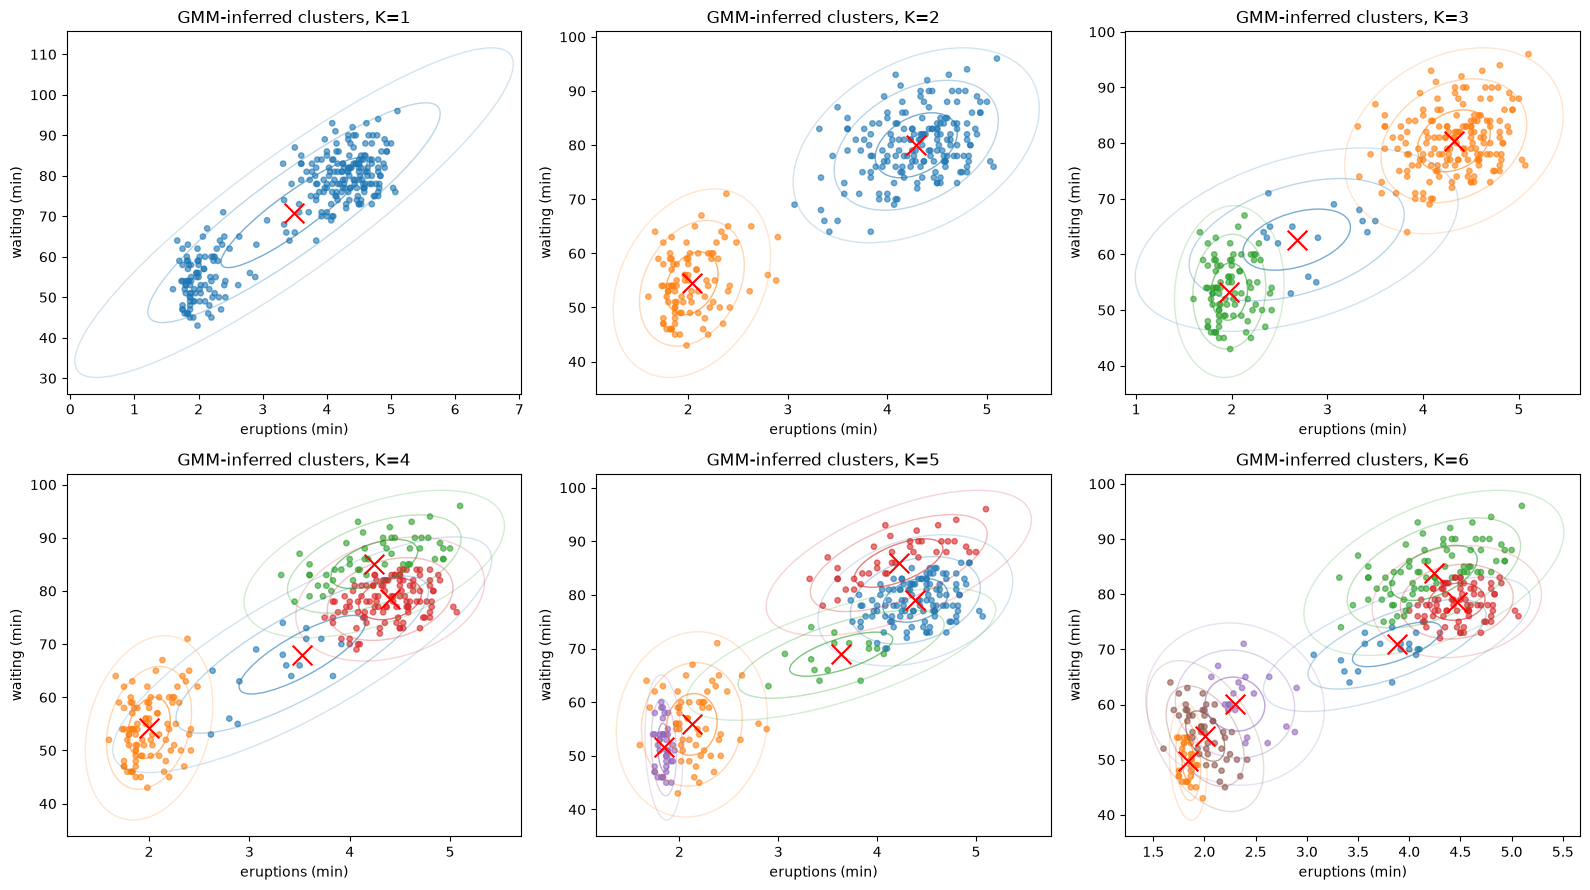

In [8]:
models = {K: fit_gmm(X, K) for K in K_RANGE}

for K, gmm in models.items():
    labels = gmm.predict(X)
    print(f"K={K}: converged={gmm.converged_}, iterations={gmm.n_iter_}, "
          f"cluster sizes={np.bincount(labels, minlength=K).tolist()}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, K in zip(axes.ravel(), [1, 2, 3, 4, 5, 6]):
    plot_clusters(ax, X, models[K], title=f"GMM-inferred clusters, K={K}")
plt.tight_layout()
plt.show()

In [9]:
gmm2 = models[2]
# order components so cluster 0 is the short-eruption group
order = np.argsort(gmm2.means_[:, 0])
remap = np.empty_like(order)
remap[order] = np.arange(len(order))

df['cluster'] = remap[gmm2.predict(X)]
df['p_cluster'] = gmm2.predict_proba(X).max(axis=1)

print(pd.DataFrame({
    'mean eruptions': gmm2.means_[order, 0].round(3),
    'mean waiting': gmm2.means_[order, 1].round(3),
    'sd eruptions': np.sqrt(gmm2.covariances_[order, 0, 0]).round(3),
    'sd waiting': np.sqrt(gmm2.covariances_[order, 1, 1]).round(3),
    'correlation': (gmm2.covariances_[order, 0, 1]
                    / np.sqrt(gmm2.covariances_[order, 0, 0] * gmm2.covariances_[order, 1, 1])).round(3),
    'weight': gmm2.weights_[order].round(3),
    'n points': np.bincount(df['cluster']),
}, index=['cluster 0 (short)', 'cluster 1 (long)']))

print(f"\npoints with max posterior < 0.9 (uncertain assignment): {(df['p_cluster'] < 0.9).sum()}")
print(df.head(10))

                   mean eruptions  mean waiting  sd eruptions  sd waiting  \
cluster 0 (short)           2.037         54.48         0.263       5.806   
cluster 1 (long)            4.290         79.97         0.412       6.002   

                   correlation  weight  n points  
cluster 0 (short)        0.286   0.356        97  
cluster 1 (long)         0.380   0.644       175  

points with max posterior < 0.9 (uncertain assignment): 1
   eruptions  waiting  cluster  p_cluster
0      3.600       79        1   1.000000
1      1.800       54        0   1.000000
2      3.333       74        1   0.999991
3      2.283       62        0   0.999989
4      4.533       85        1   1.000000
5      2.883       55        0   0.992810
6      4.700       88        1   1.000000
7      3.600       85        1   1.000000
8      1.950       51        0   1.000000
9      4.350       85        1   1.000000


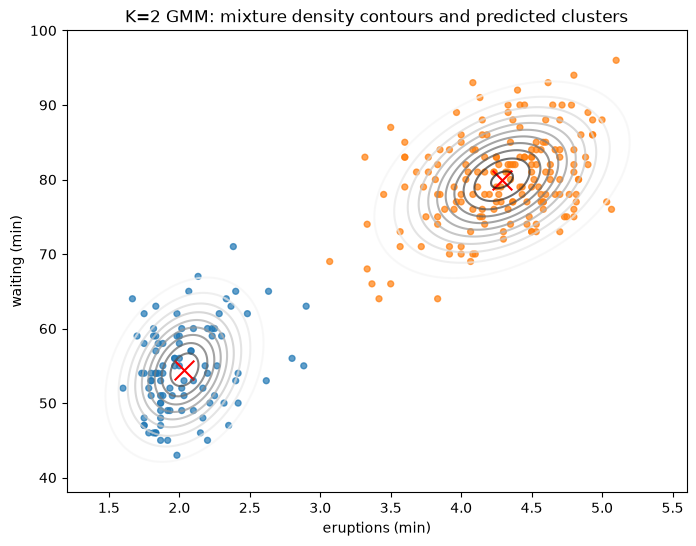

In [10]:
xx, yy = np.meshgrid(np.linspace(1.2, 5.6, 300), np.linspace(38, 100, 300))
density = np.exp(gmm2.score_samples(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
ax.contour(xx, yy, density, levels=12, cmap='Greys', alpha=0.7)
ax.scatter(df['eruptions'], df['waiting'], c=[f"C{c}" for c in df['cluster']], alpha=0.7, s=18)
ax.scatter(gmm2.means_[:, 0], gmm2.means_[:, 1], marker='x', s=200, color='red')
ax.set_xlabel("eruptions (min)")
ax.set_ylabel("waiting (min)")
ax.set_title("K=2 GMM: mixture density contours and predicted clusters")
plt.show()

## (c) Goodness-of-fit measure

The goodness-of-fit measure is the log-likelihood of the data under the GMM. Because it always increases when components are added, it is combined with a penalty for model size.

In [11]:
rows = []
kf = KFold(n_splits=5, shuffle=True, random_state=0)
for K, gmm in models.items():
    cv_ll = np.mean([fit_gmm(X[tr], K).score(X[te]) for tr, te in kf.split(X)])
    rows.append({
        'K': K,
        'n params': gmm._n_parameters(),
        'train log-lik': gmm.score(X) * len(X),
        'avg train log-lik': gmm.score(X),
        'avg held-out log-lik (5-fold)': cv_ll,
        'AIC': gmm.aic(X),
        'BIC': gmm.bic(X),
    })
fit_df = pd.DataFrame(rows).set_index('K')
print(fit_df.round(3))
print(f"\nbest K by BIC: {fit_df['BIC'].idxmin()}")
print(f"best K by AIC: {fit_df['AIC'].idxmin()}")
print(f"best K by held-out log-likelihood: {fit_df['avg held-out log-lik (5-fold)'].idxmax()}")

   n params  train log-lik  avg train log-lik  avg held-out log-lik (5-fold)  \
K                                                                              
1         5      -1289.797             -4.742                         -4.757   
2        11      -1130.264             -4.155                         -4.213   
3        17      -1119.799             -4.117                         -4.213   
4        23      -1115.443             -4.101                         -4.233   
5        29      -1104.062             -4.059                         -4.243   
6        35      -1099.921             -4.044                         -4.298   
7        41      -1092.211             -4.015                         -4.346   
8        47      -1096.045             -4.030                         -4.335   

        AIC       BIC  
K                      
1  2589.593  2607.623  
2  2282.528  2322.192  
3  2273.598  2334.897  
4  2276.886  2359.820  
5  2266.125  2370.693  
6  2269.841  2396.045  
7  2266

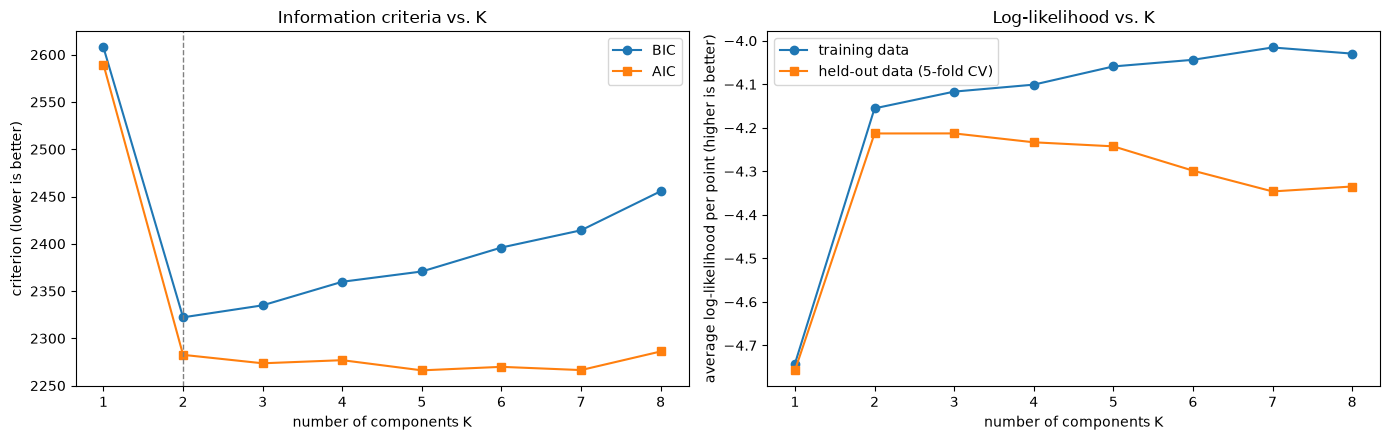

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(fit_df.index, fit_df['BIC'], 'o-', label='BIC')
axes[0].plot(fit_df.index, fit_df['AIC'], 's-', label='AIC')
axes[0].axvline(fit_df['BIC'].idxmin(), color='gray', ls='--', lw=1)
axes[0].set_xlabel("number of components K")
axes[0].set_ylabel("criterion (lower is better)")
axes[0].set_title("Information criteria vs. K")
axes[0].legend()

axes[1].plot(fit_df.index, fit_df['avg train log-lik'], 'o-', label='training data')
axes[1].plot(fit_df.index, fit_df['avg held-out log-lik (5-fold)'], 's-', label='held-out data (5-fold CV)')
axes[1].set_xlabel("number of components K")
axes[1].set_ylabel("average log-likelihood per point (higher is better)")
axes[1].set_title("Log-likelihood vs. K")
axes[1].legend()

plt.tight_layout()
plt.show()

## (d) Is a GMM suitable, and what do the clusters mean?

A GMM is a good model for this data because the scatter plot shows two separate, oval-shaped groups, and BIC is lowest at K=2. The two groups are also clearly separated, since 271 of the 272 points belong to one cluster with posterior probability above 0.9. The clusters represent two types of eruption: short eruptions (about 2 min) followed by a short wait, which make up 36% of eruptions, and long eruptions (about 4.3 min) followed by a long wait, which make up the other 64%. This means a longer eruption usually leads to a longer wait, so the length of an eruption can be used to predict when the next one will happen.